# Practical No. 05
# Image Generation using Pretrained Stable Diffusion

## Aim
To implement a pretrained Stable Diffusion model using the Hugging Face
Diffusers library to generate images from text prompts and analyze
the impact of inference steps, guidance scale, and different
sampling methods on image quality.

## Objectives
1. To understand the working of pretrained Stable Diffusion models.
2. To generate images using natural language text prompts.
3. To analyze the effect of different inference steps.
4. To study the effect of guidance scale on generated images.
5. To compare different sampling methods (Schedulers).
6. To evaluate the quality and generation time of images.

## Theory

Stable Diffusion is a pretrained text-to-image generative AI model
that generates images from natural language descriptions.

It is based on Latent Diffusion Models (LDM), which perform the
diffusion process in a compressed latent space rather than directly
on image pixels.

The model gradually removes noise from a randomly initialized
latent representation to generate an image that matches the
provided text prompt.

### Main Components

1. Text Encoder:
   Converts the input text prompt into numerical representations.

2. U-Net:
   Predicts and removes noise from the latent representation.

3. Scheduler:
   Controls the denoising process and determines how the model
   moves from noisy data toward the final image.

4. VAE Decoder:
   Converts the final latent representation into an actual image.

### Important Parameters

1. Inference Steps:
   Number of denoising iterations used during image generation.

2. Guidance Scale:
   Controls how strongly the generated image follows the
   given text prompt.

3. Sampling Method:
   Determines the mathematical procedure used during denoising.

4. Random Seed:
   Helps reproduce similar results by controlling the initial
   random noise.

## Algorithm

1. Start the program.
2. Import the required Python libraries.
3. Load the pretrained Stable Diffusion model using Hugging Face
   Diffusers.
4. Define a text prompt and negative prompt.
5. Generate a baseline image using default parameters.
6. Change the inference steps and generate multiple images.
7. Compare the generated images.
8. Change the guidance scale and analyze the output.
9. Apply different sampling methods (Schedulers).
10. Compare the generated images and execution times.
11. Generate an image using a custom text prompt.
12. Display and save all generated images.
13. Analyze the experimental results.
14. Stop.

In [5]:
!pip install -q diffusers transformers accelerate safetensors matplotlib pandas

## Implementation

### Step 1: Import Required Libraries

The required Python libraries are imported.

- PyTorch: For deep learning operations.
- Diffusers: For loading and running Stable Diffusion.
- Matplotlib: For displaying generated images.
- Pandas: For creating comparison tables.
- Time: For measuring image generation time.

In [6]:
import torch
import os
import time
import pandas as pd
import matplotlib.pyplot as plt

from diffusers import (
    StableDiffusionPipeline,
    EulerDiscreteScheduler,
    DPMSolverMultistepScheduler
)

from IPython.display import display

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    DEVICE = "cuda"
    DTYPE = torch.float16
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    DTYPE = torch.float32
    print("Running on CPU. Generation may be slow.")

os.makedirs("generated_images", exist_ok=True)

PyTorch Version: 2.14.1+cu130
CUDA Available: True
GPU: Tesla T4


In [7]:
  print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


### Step 2: Load Pretrained Stable Diffusion Model

The pretrained Stable Diffusion 2.1 Base model is loaded
from Hugging Face using the Diffusers library.

The pretrained model contains learned parameters that allow
it to generate images from text descriptions.

A GPU is recommended to reduce image generation time.

In [8]:
from diffusers import StableDiffusionPipeline
import torch

MODEL_ID = "sd2-community/stable-diffusion-2-1-base"

if torch.cuda.is_available():
    DEVICE = "cuda"
    DTYPE = torch.float16
else:
    DEVICE = "cpu"
    DTYPE = torch.float32

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    dtype=DTYPE,
    use_safetensors=True,
    token=False
)

pipe = pipe.to(DEVICE)

if DEVICE == "cuda":
    pipe.enable_attention_slicing()

print("Stable Diffusion 2.1 loaded successfully!")
print("Device:", DEVICE)

model_index.json:   0%|          | 0.00/543 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

Stable Diffusion 2.1 loaded successfully!
Device: cuda


## 4. Defining the Image Generation Function

A reusable function is created to generate images using Stable Diffusion.

The function accepts the following parameters:

- **Prompt:** Text description of the required image.
- **Negative Prompt:** Describes elements that should not appear.
- **Inference Steps:** Number of denoising steps.
- **Guidance Scale:** Controls how closely the generated image follows the prompt.
- **Scheduler:** Determines the sampling method.
- **Seed:** Helps generate reproducible results.

The generated image is saved in the `generated_images` folder.

In [9]:
from diffusers import (
    EulerDiscreteScheduler,
    DPMSolverMultistepScheduler
)
import os
import time

# Store the original scheduler configuration
original_scheduler_class = pipe.scheduler.__class__
original_scheduler_config = dict(pipe.scheduler.config)


def set_scheduler(scheduler_name):
    """Set the scheduler used for image generation."""

    if scheduler_name == "Default":
        pipe.scheduler = original_scheduler_class.from_config(
            original_scheduler_config
        )

    elif scheduler_name == "Euler":
        pipe.scheduler = EulerDiscreteScheduler.from_config(
            original_scheduler_config
        )

    elif scheduler_name == "DPM-Solver":
        pipe.scheduler = DPMSolverMultistepScheduler.from_config(
            original_scheduler_config
        )


def generate_image(
    prompt,
    negative_prompt="",
    steps=30,
    guidance=7.5,
    scheduler="Default",
    seed=42
):
    """Generate an image using Stable Diffusion."""

    set_scheduler(scheduler)

    generator = torch.Generator(device=DEVICE).manual_seed(seed)

    start_time = time.time()

    result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=steps,
        guidance_scale=guidance,
        generator=generator,
        height=512,
        width=512
    )

    elapsed_time = time.time() - start_time

    image = result.images[0]

    return image, elapsed_time


print("Image generation function defined successfully!")

Image generation function defined successfully!


## 5. Baseline Image Generation

First, an image is generated using default experimental settings.

Parameters:

- Inference Steps: 30
- Guidance Scale: 7.5
- Scheduler: Default
- Seed: 42

This image acts as the baseline for comparison with subsequent experiments.

  0%|          | 0/30 [00:00<?, ?it/s]

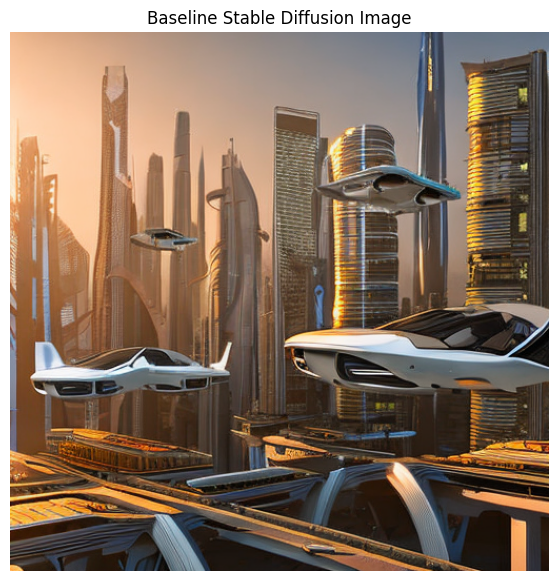

Generation time: 7.93 seconds


In [10]:
prompt = "A beautiful futuristic city with flying cars, skyscrapers, sunset lighting, highly detailed digital art"

negative_prompt = "blurry, low quality, distorted, extra objects, text, watermark"

baseline_image, baseline_time = generate_image(
    prompt=prompt,
    negative_prompt=negative_prompt,
    steps=30,
    guidance=7.5,
    scheduler="Default",
    seed=42
)

baseline_image.save("generated_images/baseline.png")

plt.figure(figsize=(7, 7))
plt.imshow(baseline_image)
plt.axis("off")
plt.title("Baseline Stable Diffusion Image")
plt.show()

print(f"Generation time: {baseline_time:.2f} seconds")

## 6. Experiment 1: Effect of Inference Steps

Inference steps represent the number of denoising iterations performed by the model.

Different inference step values are tested:

- 10 steps
- 20 steps
- 30 steps
- 50 steps

**Objective:** To observe how the number of inference steps affects image quality and generation time.

A higher number of steps may improve image details, but it also increases generation time.

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

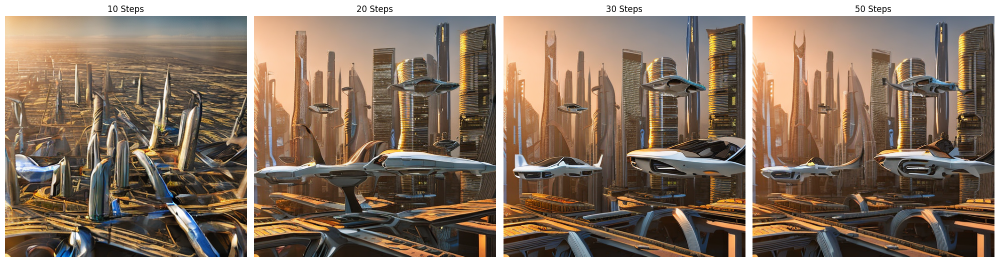

,Inference Steps,Generation Time (seconds)
0,10,2.11
1,20,3.83
2,30,5.58
3,50,9.26


In [11]:
step_values = [10, 20, 30, 50]

step_results = []

fig, axes = plt.subplots(1, 4, figsize=(20, 6))

for i, steps in enumerate(step_values):

    image, elapsed = generate_image(
        prompt=prompt,
        negative_prompt=negative_prompt,
        steps=steps,
        guidance=7.5,
        scheduler="Default",
        seed=42
    )

    image.save(f"generated_images/steps_{steps}.png")

    axes[i].imshow(image)
    axes[i].set_title(f"{steps} Steps")
    axes[i].axis("off")

    step_results.append({
        "Inference Steps": steps,
        "Generation Time (seconds)": round(elapsed, 2)
    })

plt.tight_layout()
plt.show()

step_df = pd.DataFrame(step_results)
display(step_df)

## 6. Experiment 1: Effect of Inference Steps

Inference steps represent the number of denoising iterations performed by the model.

Different inference step values are tested:

- 10 steps
- 20 steps
- 30 steps
- 50 steps

**Objective:** To observe how the number of inference steps affects image quality and generation time.

A higher number of steps may improve image details, but it also increases generation time.

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

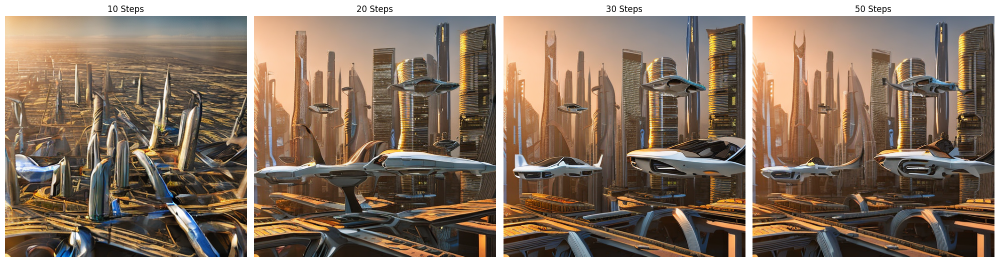

,Inference Steps,Generation Time (seconds)
0,10,2.28
1,20,4.52
2,30,6.75
3,50,9.66


In [12]:
step_values = [10, 20, 30, 50]

step_results = []

fig, axes = plt.subplots(1, 4, figsize=(20, 6))

for i, steps in enumerate(step_values):

    image, elapsed = generate_image(
        prompt=prompt,
        negative_prompt=negative_prompt,
        steps=steps,
        guidance=7.5,
        scheduler="Default",
        seed=42
    )

    image.save(f"generated_images/steps_{steps}.png")

    axes[i].imshow(image)
    axes[i].set_title(f"{steps} Steps")
    axes[i].axis("off")

    step_results.append({
        "Inference Steps": steps,
        "Generation Time (seconds)": round(elapsed, 2)
    })

plt.tight_layout()
plt.show()

step_df = pd.DataFrame(step_results)
display(step_df)

### Observation

The number of inference steps influences both image quality and generation time.

- Lower steps generally produce images faster but may contain fewer details.
- Increasing the number of steps can improve refinement and visual quality.
- Higher steps require more computation time.
- Increasing steps does not always guarantee a significant improvement in image quality.

**Conclusion:** The inference step count should be selected by balancing image quality and generation time.

## 7. Experiment 2: Effect of Guidance Scale

Guidance scale controls how strongly the generated image follows the input text prompt.

The following values are tested:

- 1.0
- 5.0
- 7.5
- 12.0

**Objective:** To understand how guidance scale affects prompt adherence and image appearance.

A low guidance scale allows more freedom to the model, whereas a high guidance scale encourages closer adherence to the prompt.

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

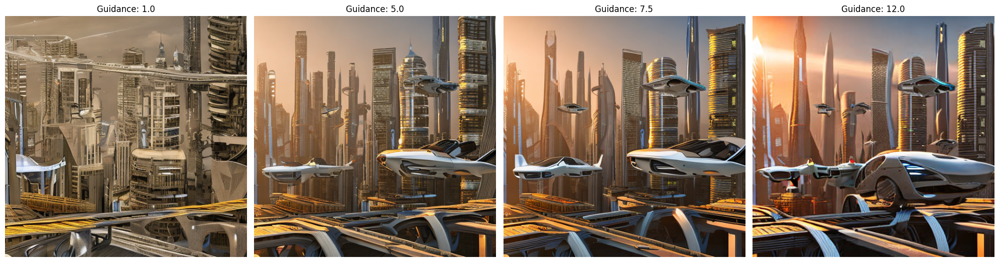

,Guidance Scale,Generation Time (seconds)
0,1.0,3.69
1,5.0,6.14
2,7.5,6.26
3,12.0,6.63


In [13]:
guidance_values = [1.0, 5.0, 7.5, 12.0]

guidance_results = []

fig, axes = plt.subplots(1, 4, figsize=(20, 6))

for i, guidance in enumerate(guidance_values):

    image, elapsed = generate_image(
        prompt=prompt,
        negative_prompt=negative_prompt,
        steps=30,
        guidance=guidance,
        scheduler="Default",
        seed=42
    )

    image.save(f"generated_images/guidance_{guidance}.png")

    axes[i].imshow(image)
    axes[i].set_title(f"Guidance: {guidance}")
    axes[i].axis("off")

    guidance_results.append({
        "Guidance Scale": guidance,
        "Generation Time (seconds)": round(elapsed, 2)
    })

plt.tight_layout()
plt.show()

guidance_df = pd.DataFrame(guidance_results)
display(guidance_df)

### Observation

Guidance scale affects how closely the generated image follows the text prompt.

- A low guidance scale gives the model more creative freedom.
- A moderate guidance scale generally provides a balance between creativity and prompt adherence.
- A very high guidance scale may produce overly strong or unnatural visual effects.

**Conclusion:** A guidance scale around 7.5 is a useful starting point for experimentation, although the best value depends on the prompt.

## 8. Experiment 3: Comparison of Sampling Methods

A scheduler determines how the model gradually removes noise during image generation.

The following schedulers are compared:

1. Default Scheduler
2. Euler Discrete Scheduler
3. DPM-Solver Multistep Scheduler

**Objective:** To compare the visual output and generation time of different sampling methods.

All other parameters are kept constant to make the comparison fair.

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

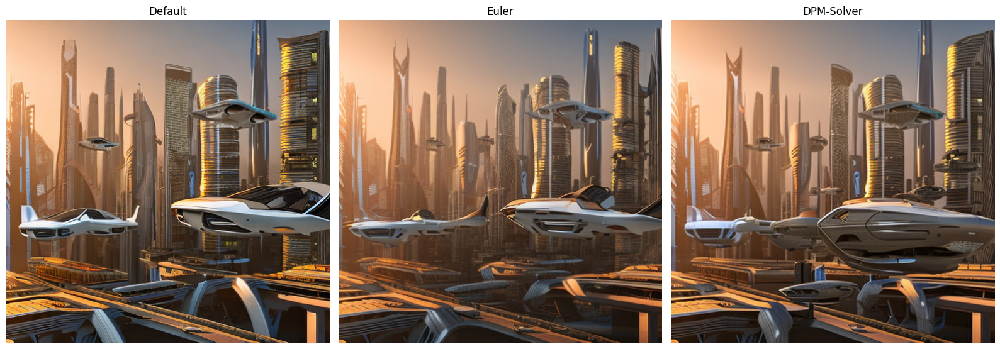

,Scheduler,Generation Time (seconds)
0,Default,6.62
1,Euler,6.58
2,DPM-Solver,6.76


In [14]:
scheduler_names = ["Default", "Euler", "DPM-Solver"]

scheduler_results = []

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

for i, scheduler_name in enumerate(scheduler_names):

    image, elapsed = generate_image(
        prompt=prompt,
        negative_prompt=negative_prompt,
        steps=30,
        guidance=7.5,
        scheduler=scheduler_name,
        seed=42
    )

    image.save(
        f"generated_images/scheduler_{scheduler_name}.png"
    )

    axes[i].imshow(image)
    axes[i].set_title(scheduler_name)
    axes[i].axis("off")

    scheduler_results.append({
        "Scheduler": scheduler_name,
        "Generation Time (seconds)": round(elapsed, 2)
    })

plt.tight_layout()
plt.show()

scheduler_df = pd.DataFrame(scheduler_results)
display(scheduler_df)

### Observation

Different schedulers can produce different image-generation characteristics.

- The Default Scheduler uses the scheduler configured in the pretrained model.
- Euler is an alternative sampling method that can produce different visual characteristics.
- DPM-Solver is designed to generate samples efficiently with fewer inference steps in suitable settings.

Generation time depends on the hardware, scheduler, inference steps, and runtime conditions.

**Conclusion:** Scheduler selection can influence image appearance and computational efficiency.

## 9. Generating an Image Using a Custom Prompt

In this experiment, a different text prompt is used to demonstrate the flexibility of the pretrained Stable Diffusion model.

The model can generate different types of images based on natural-language descriptions.

The following experiment uses a landscape prompt.

  0%|          | 0/30 [00:00<?, ?it/s]

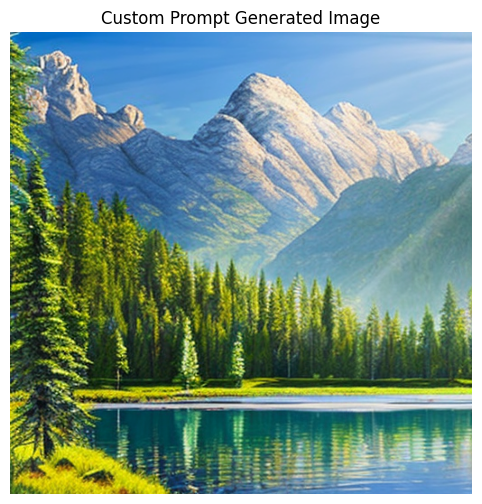

Generation time: 7.17 seconds


In [15]:
custom_prompt = (
    "A peaceful mountain landscape with a beautiful lake, "
    "green forests, snow-covered mountains, morning sunlight, "
    "realistic photography, highly detailed"
)

custom_image, custom_time = generate_image(
    prompt=custom_prompt,
    negative_prompt="blurry, low quality, distorted, watermark",
    steps=30,
    guidance=7.5,
    scheduler="Default",
    seed=100
)

custom_image.save("generated_images/custom_landscape.png")

plt.figure(figsize=(8, 6))
plt.imshow(custom_image)
plt.axis("off")
plt.title("Custom Prompt Generated Image")
plt.show()

print(f"Generation time: {custom_time:.2f} seconds")

## 10. Comparison of Experimental Results

The experiments demonstrate how different Stable Diffusion parameters affect image generation.

The following parameters were studied:

1. Inference Steps
2. Guidance Scale
3. Sampling Scheduler

The generated images and their respective generation times are compared to understand the relationship between model settings, visual output, and computational cost.

In [16]:
print("EXPERIMENT 1: INFERENCE STEPS")
display(step_df)

print("EXPERIMENT 2: GUIDANCE SCALE")
display(guidance_df)

print("EXPERIMENT 3: SAMPLING METHODS")
display(scheduler_df)

# Save experimental results
step_df.to_csv("generated_images/inference_steps_results.csv", index=False)
guidance_df.to_csv("generated_images/guidance_scale_results.csv", index=False)
scheduler_df.to_csv("generated_images/scheduler_results.csv", index=False)

print("All experimental result tables saved successfully!")

EXPERIMENT 1: INFERENCE STEPS


,Inference Steps,Generation Time (seconds)
0,10,2.28
1,20,4.52
2,30,6.75
3,50,9.66


EXPERIMENT 2: GUIDANCE SCALE


,Guidance Scale,Generation Time (seconds)
0,1.0,3.69
1,5.0,6.14
2,7.5,6.26
3,12.0,6.63


EXPERIMENT 3: SAMPLING METHODS


,Scheduler,Generation Time (seconds)
0,Default,6.62
1,Euler,6.58
2,DPM-Solver,6.76


All experimental result tables saved successfully!


## 11. Result

The pretrained Stable Diffusion 2.1 model was successfully implemented using the Hugging Face Diffusers library.

Images were generated using different text prompts.

Experiments were performed by varying inference steps, guidance scale, and sampling schedulers.

The generated images and execution times were recorded to study the effect of these parameters on image generation.

## 12. Conclusion

In this practical, a pretrained Stable Diffusion model was successfully used to generate images from text descriptions.

The experiments demonstrated that:

- Inference steps affect image refinement and generation time.
- Guidance scale influences how closely an image follows the text prompt.
- Different schedulers can produce different image outputs and computational performance.
- A fixed random seed helps make comparisons more reproducible.

Thus, Stable Diffusion provides an effective approach for text-to-image generation using pretrained deep learning models.

Submitted by

202502110008- Dhanashri Abhijit Shah

Class : TYCSE (AIML)

Batch : A3

Subject : Generative AI